# Домашняя работа 1.2. Баллистическое движение

## Жёлтый уровень: квадратичное сопротивление

Исследуется зависимость дальности полёта от угла запуска и сопротивления среды.
Начальная скорость во всех расчётах равна $v_0=20\,\mathrm{м/с}$,
ускорение свободного падения — $g=9.81\,\mathrm{м/с^2}$.
Тело стартует из точки $(0,0)$ и приземляется на уровень $y=0$.
Ось $y$ направлена вверх. Для расчёта энергий и сил принята масса $m=1\,\mathrm{кг}$.

Сначала проверяются методы Эйлера и RK4 на модели с линейным сопротивлением.
Затем методом RK4 рассчитывается движение с квадратичным сопротивлением.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from base64 import b64encode
from PIL import Image as PILImage
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.25})

g = 9.81
mass = 1.0
v0 = 20.0
h_main = 0.01
k_values = [0.0, 0.01, 0.03, 0.07]
k_example = 0.03


def initial_state(angle):
    a = np.radians(angle)
    return np.array([0.0, 0.0, v0 * np.cos(a), v0 * np.sin(a)])


def rk4_step(state, h, f):
    k1 = f(state)
    k2 = f(state + h * k1 / 2)
    k3 = f(state + h * k2 / 2)
    k4 = f(state + h * k3)
    return state + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def show_table(headers, rows):
    rows = [[str(value) for value in row] for row in rows]
    widths = [max(len(header), max(len(row[i]) for row in rows))
              for i, header in enumerate(headers)]
    for row in [headers] + rows:
        print("  ".join(value.ljust(width) for value, width in zip(row, widths)))
    print()


## 1. Проверка на линейной модели

Состояние тела задаётся вектором $(x,y,v_x,v_y)$. Уравнения движения:

$$
\dot{x}=v_x,\qquad \dot{y}=v_y,
$$

$$
\dot{v}_x=-\frac{v_x}{\tau},\qquad
\dot{v}_y=-g-\frac{v_y}{\tau}.
$$

При $v_{x0}=v_0\cos\alpha$ и $v_{y0}=v_0\sin\alpha$ точное решение имеет вид:

$$
x(t)=\tau v_{x0}\left(1-e^{-t/\tau}\right),
$$

$$
y(t)=\tau(v_{y0}+g\tau)\left(1-e^{-t/\tau}\right)-g\tau t,
$$

$$
v_x(t)=v_{x0}e^{-t/\tau},\qquad
v_y(t)=(v_{y0}+g\tau)e^{-t/\tau}-g\tau.
$$

Сравнение проводится при $\alpha=45^\circ$, $\tau=2\,\mathrm{с}$
и шагах $h=0.2,\ 0.1,\ 0.05,\ 0.025\,\mathrm{с}$.
В таблице приведена максимальная по узлам сетки ошибка положения
$\|\mathbf r_{\mathrm{числ}}-\mathbf r_{\mathrm{точн}}\|$.
Оба метода рассчитываются до времени падения точного решения;
последний шаг при необходимости сокращается.

Энергии вычисляются по формулам

$$
U=mgy,\qquad K=\frac{m}{2}(v_x^2+v_y^2),\qquad E=U+K.
$$

На первом рисунке показаны траектория и энергии при $h=0.1\,\mathrm{с}$.
На втором сравниваются точные траектории для трёх значений $\tau$:
меньшее время торможения соответствует более сильному сопротивлению.

Метод  h, с   Максимальная ошибка положения, м
Эйлер  0.2    1.4057e+00                      
Эйлер  0.1    6.8769e-01                      
Эйлер  0.05   3.4020e-01                      
Эйлер  0.025  1.6921e-01                      
RK4    0.2    2.4396e-05                      
RK4    0.1    1.4624e-06                      
RK4    0.05   8.9515e-08                      
RK4    0.025  5.5367e-09                      



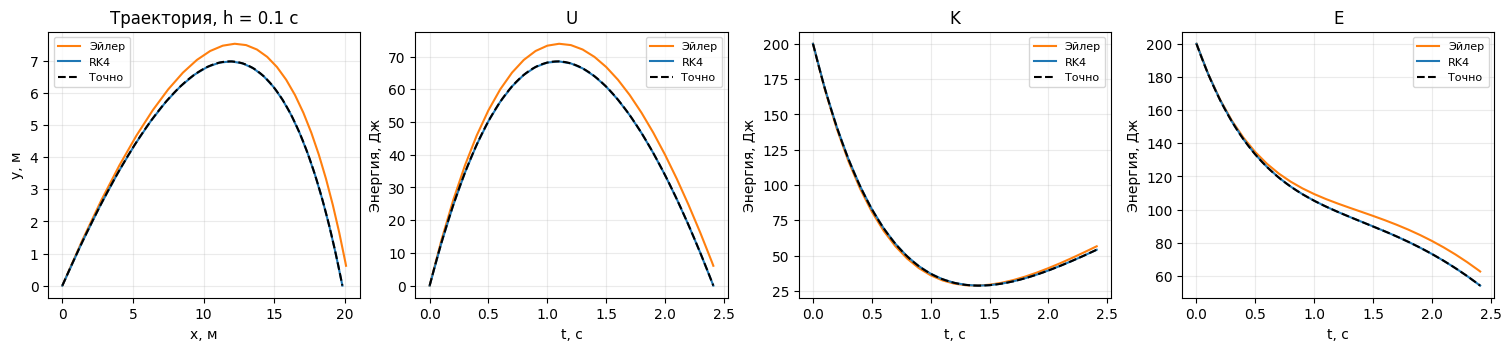

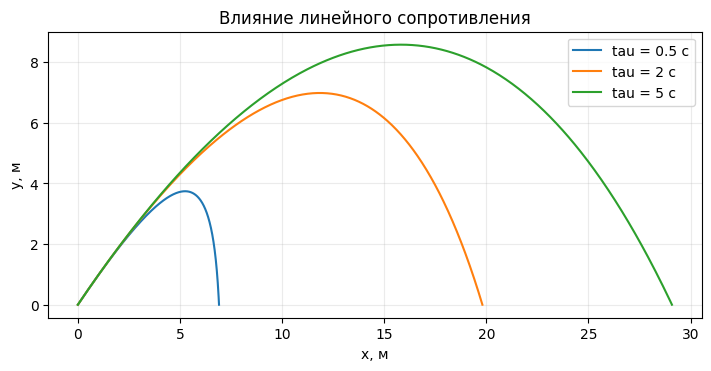

In [2]:
def linear_rhs(state, tau):
    x, y, vx, vy = state
    return np.array([vx, vy, -vx / tau, -g - vy / tau])


def linear_exact(t, angle, tau):
    t = np.atleast_1d(t)
    vx0, vy0 = initial_state(angle)[2:]
    q = -np.expm1(-t / tau)
    return np.column_stack((tau * vx0 * q,
                            tau * (vy0 + g * tau) * q - g * tau * t,
                            vx0 * (1 - q), (vy0 + g * tau) * (1 - q) - g * tau))


def linear_landing(angle, tau):
    vy0 = initial_state(angle)[3]
    left = tau * np.log1p(vy0 / (g * tau))
    right = max(1.0, 2 * left)
    while linear_exact(right, angle, tau)[0, 1] > 0:
        right *= 2
    for _ in range(45):
        middle = (left + right) / 2
        if linear_exact(middle, angle, tau)[0, 1] > 0:
            left = middle
        else:
            right = middle
    return (left + right) / 2


def linear_solution(angle, tau, h, method):
    t_end = linear_landing(angle, tau)
    t = np.minimum(np.arange(int(np.ceil(t_end / h)) + 1) * h, t_end)
    states = np.empty((len(t), 4))
    states[0] = initial_state(angle)
    f = lambda state: linear_rhs(state, tau)
    for i in range(len(t) - 1):
        dt = t[i + 1] - t[i]
        states[i + 1] = (states[i] + dt * f(states[i]) if method == "Эйлер"
                         else rk4_step(states[i], dt, f))
    return t, states


def energies(states):
    u = mass * g * states[:, 1]
    kinetic = mass * np.sum(states[:, 2:]**2, axis=1) / 2
    return u, kinetic, u + kinetic


linear_rows = []
for method in ["Эйлер", "RK4"]:
    for h in [0.2, 0.1, 0.05, 0.025]:
        t, states = linear_solution(45, 2, h, method)
        exact = linear_exact(t, 45, 2)
        error = np.max(np.linalg.norm(states[:, :2] - exact[:, :2], axis=1))
        linear_rows.append([method, h, f"{error:.4e}"])
show_table(["Метод", "h, с", "Максимальная ошибка положения, м"], linear_rows)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), layout="constrained")
for method, color in [("Эйлер", "tab:orange"), ("RK4", "tab:blue")]:
    t, states = linear_solution(45, 2, 0.1, method)
    axes[0].plot(states[:, 0], states[:, 1], color=color, label=method)
    for ax, values in zip(axes[1:], energies(states)):
        ax.plot(t, values, color=color, label=method)
t_exact = np.linspace(0, linear_landing(45, 2), 500)
exact = linear_exact(t_exact, 45, 2)
axes[0].plot(exact[:, 0], exact[:, 1], "k--", label="Точно")
axes[0].set(title="Траектория, h = 0.1 с", xlabel="x, м", ylabel="y, м")
for ax, values, title in zip(axes[1:], energies(exact), ["U", "K", "E"]):
    ax.plot(t_exact, values, "k--", label="Точно")
    ax.set(title=title, xlabel="t, с", ylabel="Энергия, Дж")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
for tau in [0.5, 2.0, 5.0]:
    t = np.linspace(0, linear_landing(45, tau), 500)
    states = linear_exact(t, 45, tau)
    ax.plot(states[:, 0], states[:, 1], label=f"tau = {tau:g} с")
ax.set(title="Влияние линейного сопротивления", xlabel="x, м", ylabel="y, м")
ax.legend()
plt.show()


## 2. Квадратичное сопротивление

В этой модели уравнения для скорости заменяются на

$$
\dot{v}_x=-k\sqrt{v_x^2+v_y^2}\,v_x,
$$

$$
\dot{v}_y=-g-k\sqrt{v_x^2+v_y^2}\,v_y.
$$

Коэффициент $k$ имеет размерность $\mathrm{м^{-1}}$.
Сила сопротивления равна $\mathbf F_{\mathrm{с}}=-mk|\mathbf v|\mathbf v$.
Рассматриваются $k=0,\ 0.01,\ 0.03,\ 0.07\,\mathrm{м^{-1}}$.

Движение рассчитывается методом RK4. Если на очередном шаге высота
меняет знак с положительного на отрицательный, внутри этого шага
делением пополам ищется время достижения $y=0$.
Для каждой пробной длительности шаг RK4 повторяется из последнего состояния над землёй.
Дальность равна координате $x$ в уточнённый момент падения.

При $k=0$ результат проверяется по формулам

$$
R=\frac{v_0^2\sin(2\alpha)}{g},\qquad
T=\frac{2v_0\sin\alpha}{g}.
$$

In [3]:
def quadratic_rhs(state, k):
    x, y, vx, vy = state
    speed = np.hypot(vx, vy)
    return np.array([vx, vy, -k * speed * vx, -g - k * speed * vy])


def locate_zero(state, h, f, component):
    left, right = 0.0, h
    for _ in range(40):
        middle = (left + right) / 2
        trial = rk4_step(state, middle, f)
        if trial[component] > 0:
            left = middle
        else:
            right = middle
    dt = (left + right) / 2
    return dt, rk4_step(state, dt, f)


def flight(angle, k, h=h_main):
    if not (0 < angle < 90 and k >= 0 and h > 0):
        raise ValueError("Нужны 0 < angle < 90, k >= 0 и h > 0.")
    f = lambda state: quadratic_rhs(state, k)
    times = [0.0]
    states = [initial_state(angle)]
    for _ in range(int(30 / h) + 1):
        new_state = rk4_step(states[-1], h, f)
        if new_state[1] <= 0 and new_state[3] < 0:
            dt, landing = locate_zero(states[-1], h, f, 1)
            assert abs(landing[1]) < 1e-8
            landing[1] = 0.0
            times.append(times[-1] + dt)
            states.append(landing)
            return np.array(times), np.array(states)
        times.append(times[-1] + h)
        states.append(new_state)
    raise RuntimeError("За 30 секунд падение не найдено.")


free_rows = []
for angle in [1, 15, 45, 75, 89]:
    t, states = flight(angle, 0, 0.08)
    a = np.radians(angle)
    exact_range = v0**2 * np.sin(2 * a) / g
    exact_time = 2 * v0 * np.sin(a) / g
    error = abs(states[-1, 0] - exact_range)
    assert error < 1e-8
    assert abs(t[-1] - exact_time) < 1e-9
    free_rows.append([angle, f"{states[-1, 0]:.8f}", f"{exact_range:.8f}", f"{error:.2e}"])
show_table(["Угол, °", "Расчётная дальность, м", "Точная дальность, м", "Ошибка, м"], free_rows)


Угол, °  Расчётная дальность, м  Точная дальность, м  Ошибка, м
1        1.42301719              1.42301719           6.69e-13 
15       20.38735984             20.38735984          6.68e-13 
45       40.77471967             40.77471967          1.21e-13 
75       20.38735984             20.38735984          5.33e-14 
89       1.42301719              1.42301719           2.22e-16 



## 3. Зависимость дальности от угла запуска

Для каждого $k$ перебираются углы от $1^\circ$ до $89^\circ$ с шагом $1^\circ$.
Затем в пределах $\pm1^\circ$ от найденного угла перебор повторяется с шагом $0.02^\circ$.
Шаг интегрирования равен $h=0.01\,\mathrm{с}$.
Кружками на графике отмечены максимумы, найденные на уточнённой сетке углов.

k, м⁻¹  Угол максимума, °  Максимальная дальность, м
0.0     45.00              40.774720                
0.01    42.98              31.391472                
0.03    40.40              22.398672                
0.07    37.48              14.987275                



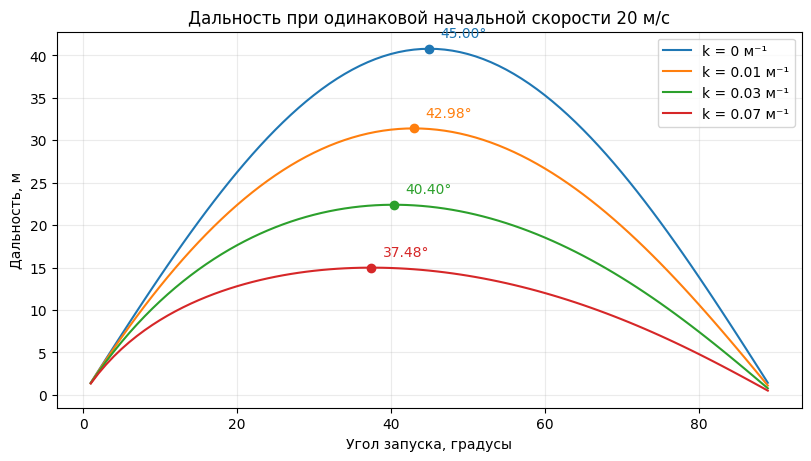

In [4]:
angles = np.arange(1.0, 90.0, 1.0)


def scan_angles(k, h, angle_step=0.02):
    ranges = np.array([flight(angle, k, h)[1][-1, 0] for angle in angles])
    best = angles[np.argmax(ranges)]
    left = max(1.0, best - 1.0)
    right = min(89.0, best + 1.0)
    fine_angles = np.arange(left, right + angle_step / 2, angle_step)
    fine_ranges = np.array([flight(angle, k, h)[1][-1, 0] for angle in fine_angles])
    j = np.argmax(fine_ranges)
    return ranges, float(fine_angles[j]), float(fine_ranges[j])


maxima = {}
range_curves = {}
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
for k in k_values:
    ranges, best_angle, best_range = scan_angles(k, h_main)
    maxima[k] = (best_angle, best_range)
    range_curves[k] = ranges
    line, = ax.plot(angles, ranges, label=f"k = {k:g} м⁻¹")
    ax.plot(best_angle, best_range, "o", color=line.get_color())
    ax.annotate(f"{best_angle:.2f}°", (best_angle, best_range),
                xytext=(8, 8), textcoords="offset points", color=line.get_color())
ax.set(xlabel="Угол запуска, градусы", ylabel="Дальность, м",
       title="Дальность при одинаковой начальной скорости 20 м/с")
ax.legend()
plt.show()
show_table(["k, м⁻¹", "Угол максимума, °", "Максимальная дальность, м"],
           [[k, f"{a:.2f}", f"{r:.6f}"] for k, (a, r) in maxima.items()])
assert abs(maxima[0.0][0] - 45.0) < 1e-8


## 4. Проверка сходимости

Поиск максимума повторяется при $h=0.08,\ 0.04,\ 0.02,\ 0.01\,\mathrm{с}$.
В последнем столбце первой таблицы указана разность дальностей на соседних сетках.
Шаг перебора углов во всех этих расчётах равен $0.02^\circ$.

Во второй таблице проверяется дальность при фиксированных
$\alpha=40^\circ$ и $k=0.03\,\mathrm{м^{-1}}$.
За опорное значение принят расчёт с шагом $0.00125\,\mathrm{с}$.
По отношению ошибок на двух самых мелких проверяемых шагах оценивается порядок:

$$
p=\log_2\frac{\varepsilon(0.02)}{\varepsilon(0.01)}.
$$

В третьей таблице меняется только шаг перебора углов при $h=0.01\,\mathrm{с}$
и $k=0.03\,\mathrm{м^{-1}}$. Это позволяет отдельно оценить влияние угловой сетки.

In [5]:
convergence = []
step_changes = []
for k in k_values:
    previous = None
    for h in [0.08, 0.04, 0.02, 0.01]:
        if h == h_main:
            best_angle, best_range = maxima[k]
        else:
            _, best_angle, best_range = scan_angles(k, h)
        change = None if previous is None else abs(best_range - previous)
        convergence.append([k, h, f"{best_angle:.2f}", f"{best_range:.8f}",
                            "—" if change is None else f"{change:.3e}"])
        if h == h_main:
            step_changes.append(change)
        previous = best_range
show_table(["k, м⁻¹", "h, с", "Угол, °", "R_max, м", "Изменение R_max, м"], convergence)

reference_range = flight(40, k_example, 0.00125)[1][-1, 0]
fixed_errors = []
fixed_rows = []
for h in [0.08, 0.04, 0.02, 0.01]:
    t, states = flight(40, k_example, h)
    error = abs(states[-1, 0] - reference_range)
    fixed_errors.append(error)
    fixed_rows.append([h, f"{t[-1]:.9f}", f"{states[-1, 0]:.9f}", f"{error:.3e}"])
show_table(["h, с", "Время падения при 40°, с", "Дальность при 40°, м", "Разность с опорным расчётом, м"], fixed_rows)
assert fixed_errors[-1] < fixed_errors[0]
observed_order = np.log2(fixed_errors[-2] / fixed_errors[-1])
print(f"Оценка порядка по двум мелким шагам: {observed_order:.2f}")

angular_rows = []
coarse_best = angles[np.argmax(range_curves[k_example])]
for angle_step in [1.0, 0.2, 0.1, 0.02]:
    fine = np.arange(coarse_best - 1, coarse_best + 1 + angle_step / 2, angle_step)
    distances = [flight(angle, k_example, h_main)[1][-1, 0] for angle in fine]
    j = np.argmax(distances)
    angular_rows.append([angle_step, f"{fine[j]:.2f}", f"{distances[j]:.8f}"])
show_table(["Шаг по углу, °", "Угол максимума при k=0.03, °", "Дальность, м"], angular_rows)


k, м⁻¹  h, с  Угол, °  R_max, м     Изменение R_max, м
0.0     0.08  45.00    40.77471967  —                 
0.0     0.04  45.00    40.77471967  2.558e-13         
0.0     0.02  45.00    40.77471967  1.350e-13         
0.0     0.01  45.00    40.77471967  1.990e-13         
0.01    0.08  42.98    31.39147161  —                 
0.01    0.04  42.98    31.39147193  3.162e-07         
0.01    0.02  42.98    31.39147195  1.939e-08         
0.01    0.01  42.98    31.39147195  1.202e-09         
0.03    0.08  40.40    22.39866698  —                 
0.03    0.04  40.40    22.39867208  5.106e-06         
0.03    0.02  40.40    22.39867239  3.040e-07         
0.03    0.01  40.40    22.39867240  1.853e-08         
0.07    0.08  37.48    14.98722005  —                 
0.07    0.04  37.48    14.98727161  5.157e-05         
0.07    0.02  37.48    14.98727450  2.886e-06         
0.07    0.01  37.48    14.98727467  1.703e-07         

h, с  Время падения при 40°, с  Дальность при 40°, м  Разность с

## 5. Симметрия траектории

Сравниваются полёты под углом $45^\circ$ при $k=0$ и $k=0.03\,\mathrm{м^{-1}}$.
Пунктиром показано отражение траектории относительно прямой $x=R/2$.
Совпадение двух кривых означает зеркальную симметрию.

Момент достижения вершины уточняется по условию $v_y=0$.
В таблице приведены времена подъёма и спуска, отношение $x_{\mathrm{вершины}}/R$
и угол падения относительно горизонтали, взятый по модулю.
Дополнительно проверяется убывание механической энергии при сопротивлении:

$$
\frac{dE}{dt}=-mk|\mathbf v|^3\leq0.
$$

k, м⁻¹  Подъём, с  Спуск, с  x_вершины / R  Угол падения, °
0.0     1.4416     1.4416    0.5000         45.00          
0.03    1.1152     1.2759    0.5587         58.80          



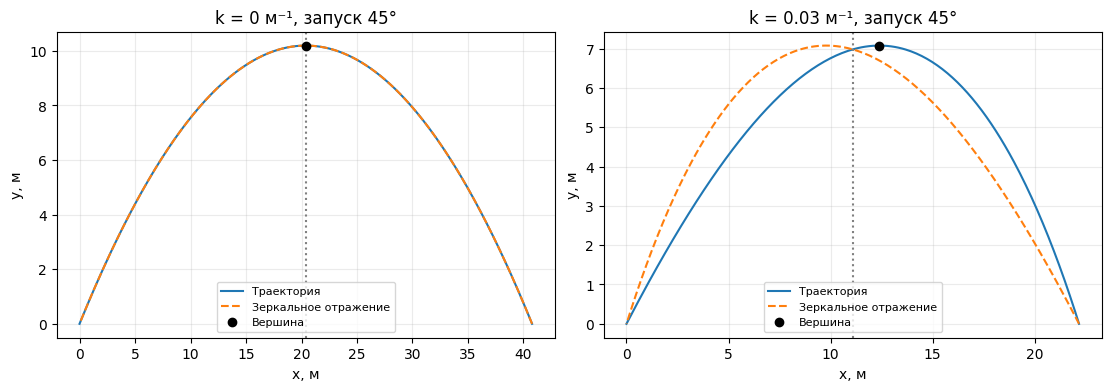

In [6]:
def apex_of_flight(t, states, k):
    j = np.flatnonzero((states[:-1, 3] > 0) & (states[1:, 3] <= 0))[0]
    f = lambda state: quadratic_rhs(state, k)
    dt, apex = locate_zero(states[j], t[j + 1] - t[j], f, 3)
    return t[j] + dt, apex


symmetry = {}
symmetry_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, k in zip(axes, [0.0, k_example]):
    t, states = flight(45, k, h_main)
    up_time, apex = apex_of_flight(t, states, k)
    down_time = t[-1] - up_time
    distance = states[-1, 0]
    apex_fraction = apex[0] / distance
    landing_angle = np.degrees(np.arctan2(-states[-1, 3], states[-1, 2]))
    symmetry[k] = (up_time, down_time, apex_fraction, landing_angle)
    symmetry_rows.append([k, f"{up_time:.4f}", f"{down_time:.4f}",
                          f"{apex_fraction:.4f}", f"{landing_angle:.2f}"])
    ax.plot(states[:, 0], states[:, 1], label="Траектория")
    ax.plot(distance - states[:, 0], states[:, 1], "--", label="Зеркальное отражение")
    ax.axvline(distance / 2, color="gray", linestyle=":")
    ax.plot(apex[0], apex[1], "ko", label="Вершина")
    ax.set(title=f"k = {k:g} м⁻¹, запуск 45°", xlabel="x, м", ylabel="y, м")
    ax.legend(fontsize=8)
plt.show()
show_table(["k, м⁻¹", "Подъём, с", "Спуск, с", "x_вершины / R", "Угол падения, °"], symmetry_rows)

t_example, states_example = flight(45, k_example, h_main)
energy = energies(states_example)[2]
assert np.max(np.diff(energy)) < 1e-8


## 6. Анимация полёта одного тела

Параметры запуска: $\alpha=45^\circ$, $k=0.03\,\mathrm{м^{-1}}$.
Показаны траектория, вектор скорости, сила тяжести и сила сопротивления.
Стрелки сил имеют общий масштаб; масштаб скорости указан отдельно в легенде.
После приземления стрелки скрываются, поскольку удар в модели не рассматривается.

Координаты кадров интерполируются между узлами численного решения.
Для определения дальности используется уточнённая точка падения из раздела 2.


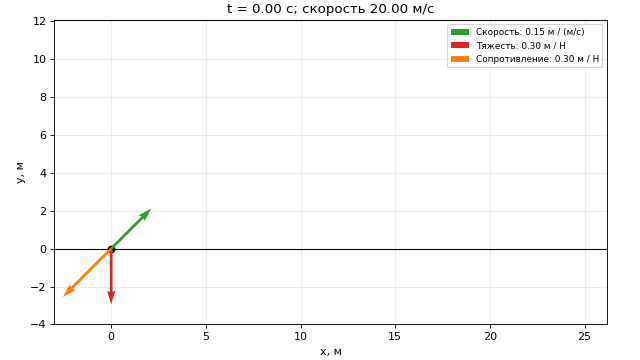

In [7]:
def show_animation(fig, update, frame_count):
    frames = []
    for i in range(frame_count):
        update(i)
        fig.canvas.draw()
        frame = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB")
        frames.append(frame)

    buffer = BytesIO()
    frames[0].save(buffer, format="GIF", save_all=True, append_images=frames[1:],
                   duration=50, loop=0)
    plt.close(fig)
    data = b64encode(buffer.getvalue()).decode("ascii")
    display(HTML(f'<img alt="Анимация полёта" src="data:image/gif;base64,{data}">'))


def sample_flight(t, states, times):
    return np.column_stack([np.interp(times, t, states[:, j]) for j in range(4)])


single_times = np.linspace(0, t_example[-1] + 0.35, 96)
single_motion = sample_flight(t_example, states_example, single_times)
fig_single, ax_single = plt.subplots(figsize=(8, 4.5), dpi=80, layout="constrained")
single_trail, = ax_single.plot([], [], color="tab:blue", linewidth=1.5)
single_body, = ax_single.plot([], [], "ko", markersize=6)
single_arrows = []
for color, label in [("tab:green", "Скорость: 0.15 м / (м/с)"),
                     ("tab:red", "Тяжесть: 0.30 м / Н"),
                     ("tab:orange", "Сопротивление: 0.30 м / Н")]:
    arrow = ax_single.quiver([0], [0], [0], [0], angles="xy", scale_units="xy",
                             scale=1, color=color, label=label, width=0.005, zorder=4)
    single_arrows.append(arrow)
ax_single.axhline(0, color="black", linewidth=1)
ax_single.set(xlim=(-3, states_example[-1, 0] + 4),
              ylim=(-4, states_example[:, 1].max() + 5),
              aspect="equal", xlabel="x, м", ylabel="y, м")
ax_single.legend(loc="upper right", fontsize=8)
single_title = ax_single.set_title("")


def update_single(frame):
    state = single_motion[frame]
    v = state[2:]
    landed = single_times[frame] >= t_example[-1]
    vectors = [0.15 * v,
               0.30 * np.array([0.0, -mass * g]),
               -0.30 * mass * k_example * np.linalg.norm(v) * v]
    single_trail.set_data(single_motion[:frame + 1, 0], single_motion[:frame + 1, 1])
    single_body.set_data([state[0]], [state[1]])
    for arrow, vector in zip(single_arrows, vectors):
        arrow.set_offsets(state[:2].reshape(1, 2))
        arrow.set_UVC([vector[0]], [vector[1]])
        arrow.set_visible(not landed)
    status = "касание земли" if landed else f"скорость {np.linalg.norm(v):.2f} м/с"
    single_title.set_text(f"t = {single_times[frame]:.2f} с; {status}")


show_animation(fig_single, update_single, len(single_times))


## 7. Одновременный запуск десяти тел

Углы запуска: $10^\circ,\ 18^\circ,\ 26^\circ,\ldots,\ 82^\circ$.
Все тела стартуют из начала координат при $t=0$ со скоростью $20\,\mathrm{м/с}$.
Слева показано движение без сопротивления, справа — при $k=0.03\,\mathrm{м^{-1}}$.
Панели используют общую временную шкалу и одинаковые масштабы осей.
Одинаковым цветом обозначен один угол запуска; крестиками отмечены точки падения.


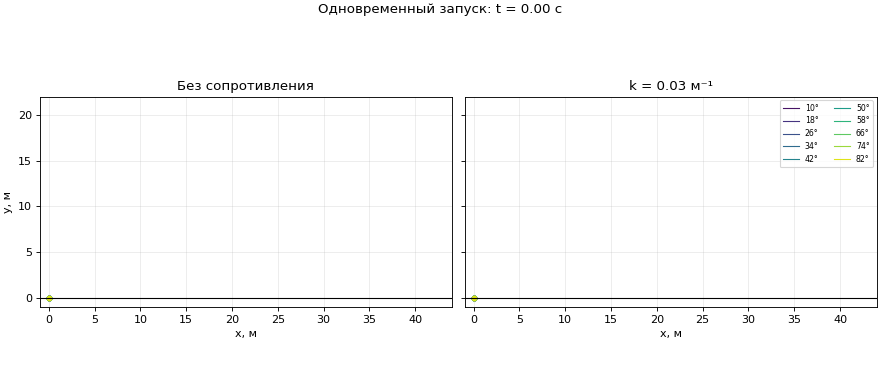

In [8]:
launch_angles = np.arange(10.0, 83.0, 8.0)
launch_colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(launch_angles)))
ensemble_flights = [[flight(angle, k, h_main) for angle in launch_angles]
                   for k in [0.0, k_example]]
last_landing = max(t[-1] for panel in ensemble_flights for t, states in panel)
ensemble_times = np.linspace(0, last_landing + 0.4, 121)
ensemble_motion = [[sample_flight(t, states, ensemble_times) for t, states in panel]
                   for panel in ensemble_flights]

fig_ensemble, ensemble_axes = plt.subplots(1, 2, figsize=(11, 4.8), dpi=80,
                                          sharex=True, sharey=True, layout="constrained")
ensemble_artists = []
for ax, k in zip(ensemble_axes, [0.0, k_example]):
    group = []
    for angle, color in zip(launch_angles, launch_colors):
        trail, = ax.plot([], [], color=color, linewidth=1, label=f"{angle:g}°")
        body, = ax.plot([], [], "o", color=color, markersize=4)
        mark, = ax.plot([], [], "x", color=color, markersize=7, markeredgewidth=1.6)
        group.append((trail, body, mark))
    ensemble_artists.append(group)
    ax.set(xlim=(-1, 44), ylim=(-1, 22), aspect="equal", xlabel="x, м",
           title="Без сопротивления" if k == 0 else f"k = {k:g} м⁻¹")
    ax.axhline(0, color="black", linewidth=1)
ensemble_axes[0].set_ylabel("y, м")
ensemble_axes[1].legend(ncol=2, fontsize=7, loc="upper right")
ensemble_title = fig_ensemble.suptitle("")


def update_ensemble(frame):
    now = ensemble_times[frame]
    for panel in range(2):
        for i, (trail, body, mark) in enumerate(ensemble_artists[panel]):
            t, states = ensemble_flights[panel][i]
            motion = ensemble_motion[panel][i]
            trail.set_data(motion[:frame + 1, 0], motion[:frame + 1, 1])
            if now >= t[-1]:
                body.set_data([], [])
                mark.set_data([states[-1, 0]], [0.0])
            else:
                body.set_data([motion[frame, 0]], [motion[frame, 1]])
                mark.set_data([], [])
    ensemble_title.set_text(f"Одновременный запуск: t = {now:.2f} с")


show_animation(fig_ensemble, update_ensemble, len(ensemble_times))


## 8. Результаты и выводы

Без сопротивления максимальная дальность равна 40.775 м при угле 45°,
что совпадает с аналитическим решением. При $k=0.01\,\mathrm{м^{-1}}$
максимум составляет 31.391 м при 42.98°, при $k=0.03\,\mathrm{м^{-1}}$ —
22.399 м при 40.40°, а при $k=0.07\,\mathrm{м^{-1}}$ — 14.987 м при 37.48°.
В рассмотренных случаях сопротивление уменьшает дальность и смещает оптимальный угол ниже 45°.
Более высокий угол увеличивает время полёта, в течение которого сопротивление
уменьшает горизонтальную скорость; преимущество такого запуска по дальности снижается.

При запуске под 45° без сопротивления времена подъёма и спуска равны 1.442 с,
а вершина находится посередине дальности. При $k=0.03\,\mathrm{м^{-1}}$
подъём занимает 1.115 с, спуск — 1.276 с; вершина находится на 55.9% дальности.
Угол падения равен 58.8°. Нисходящая часть траектории круче восходящей,
и зеркальная симметрия нарушается.

При уменьшении шага с 0.02 до 0.01 с максимальное изменение дальности
среди четырёх значений $k$ составило $1.70\cdot10^{-7}\,\mathrm{м}$.
Оценка порядка RK4 при фиксированном угле равна 4.02.
Изменение шага времени не влияет на приведённые дальности, округлённые до 0.001 м.
Оптимальные углы найдены перебором с шагом 0.02°; меньшие изменения этот перебор не различает.